In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
# Annualized return

# Dummy data
initial_value = 10_000
final_value = 15_000
years = 5

# Compute compound annual growth rate (CAGR)
cagr = (final_value / initial_value) ** (1 / years) - 1
print(cagr)

0.08447177119769855


In [ ]:
# Sharpe ratio

# Dummy data
Rp = 0.1 # portfolio return
Rf = 0.01 # risk-free rate
sd = 0.2 # standard deviation

# Compute Sharpe ratio
sharpe_ratio = (Rp - Rf) / sd
print(sharpe_ratio)

0.45


-0.07261655500647125


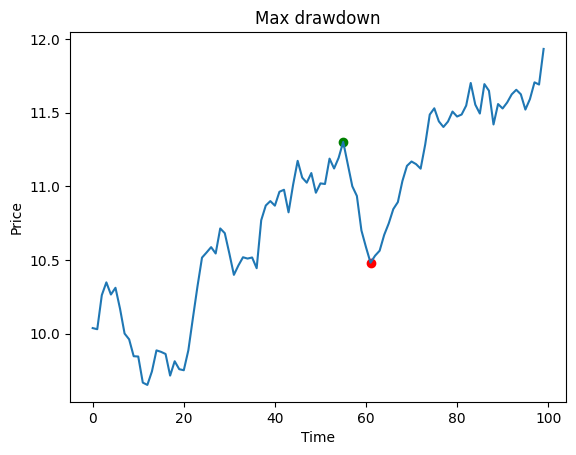

In [ ]:
# Maximum drawdown

# Dummy data
N = 100 # number of data points
prices = 10 * np.exp(np.cumsum(np.random.randn(N) * 0.01 + 0.002))
plt.plot(prices)

# Compute max drawdown
max_drawdown = 0 # initial value
current_peak = prices[0]
current_peak_index = 0
peak_for_mdd = current_peak # keep track of which peak led to mdd
trough_for_mdd = current_peak # keep track of which trough led to mdd
peak_index = 0
trough_index = 0

for i, price in enumerate(prices):
  # Update the running peak if a new high is found
  if price > current_peak:
    current_peak = price
    current_peak_index = i

  # Calculate the drawdown from the current running peak
  drawdown = (price - current_peak) / current_peak

  # Update maximum drawdown if this is the worst drop seen so far
  if drawdown < max_drawdown:
    max_drawdown = drawdown
    peak_for_mdd = current_peak
    trough_for_mdd = price
    peak_index = current_peak_index
    trough_index = i

print(max_drawdown)
plt.title("Max drawdown")
plt.xlabel("Time")
plt.ylabel("Price")
plt.scatter(peak_index, peak_for_mdd, color='g')
plt.scatter(trough_index, trough_for_mdd, color='r')
plt.show();

In [ ]:
# A simpler loop if you don't want to keep track of where the peak/trough is
# Compute max drawdown
max_drawdown = 0.0 # initial value
current_peak = prices[0]

for price in prices:
  # Update the running peak if a new high is found
  if price > current_peak:
    current_peak = price

  # Calculate the drawdown from the current running peak
  drawdown = (price - current_peak) / current_peak

  # Update maximum drawdown if this is the worst drop seen so far
  if drawdown < max_drawdown:
    max_drawdown = drawdown

print(max_drawdown)

-0.07261655500647125


In [ ]:
# Win rate

num_wins = 5
num_total_trades = 10

win_rate = num_wins / num_total_trades
print(win_rate)

0.5


In [ ]:
# Super simple trading algorithm
np.random.seed(123)

# --------------------------------------------------
# Generate price series
# --------------------------------------------------
N = 100
prices = 10 * np.exp(np.cumsum(np.random.randn(N) * 0.01 + 0.002))

# --------------------------------------------------
# Generate random position vector (0 or 1)
# Don't switch too often
# --------------------------------------------------
position = np.zeros(N, dtype=int)

for t in range(1, N):
    if np.random.rand() < 0.05:  # 5% chance of switching
        position[t] = 1 - position[t-1]
    else:
        position[t] = position[t-1]

# --------------------------------------------------
# Compute daily PnL
# --------------------------------------------------
returns = np.zeros(N)
returns[1:] = prices[1:] / prices[:-1] - 1

# Position held from previous day
pnl = position[:-1] * returns[1:]

# Equity curve
equity = np.concatenate([[1], np.cumprod(1 + pnl)])

# --------------------------------------------------
# Compute trade-level win rate
# --------------------------------------------------
trades = []
entries = []
exits = []

in_trade = False

for t in range(N):
    if not in_trade and position[t] == 1:
        entry_idx = t
        entry_price = prices[t]
        in_trade = True

    elif in_trade and position[t] == 0:
        exit_idx = t
        exit_price = prices[t]

        trade_return = exit_price / entry_price - 1
        trades.append(trade_return)
        entries.append(entry_idx)
        exits.append(exit_idx)

        in_trade = False

# Close any open trade at the end
if in_trade:
    trade_return = prices[-1] / entry_price - 1
    trades.append(trade_return)

wins = sum(r > 0 for r in trades)
num_trades = len(trades)

win_rate = wins / num_trades if num_trades > 0 else np.nan

print("Number of trades:", num_trades)
print("Winning trades:", wins)
print("Win rate:", round(win_rate, 3))

# Optional: inspect results
df = pd.DataFrame({
    "price": prices,
    "position": position,
})

print(df.head())

Number of trades: 3
Winning trades: 2
Win rate: 0.667
       price  position
0   9.911828         0
1  10.031220         0
2  10.079786         0
3   9.948971         0
4   9.911375         0


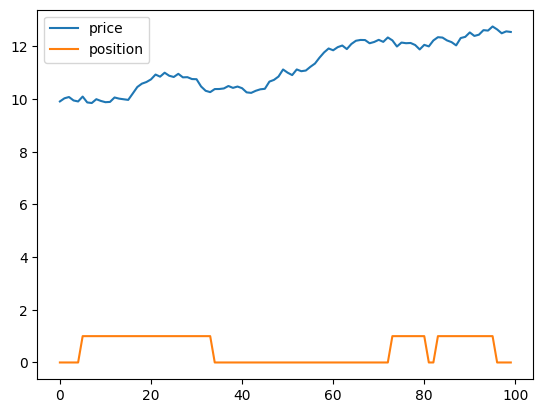

In [ ]:
df.plot();

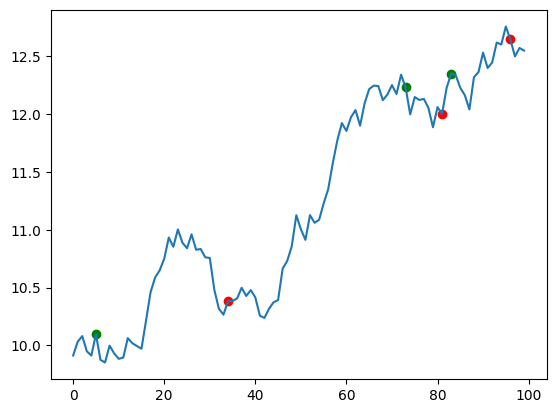

In [ ]:
plt.plot(prices)
plt.scatter(entries, prices[entries], color='g')
plt.scatter(exits, prices[exits], color='r')
plt.show();

In [ ]:
# Find position changes
changes = np.diff(position, prepend=0)

# Entry points: 0 -> 1
entries2 = np.where(changes == 1)[0]

# Exit points: 1 -> 0
exits2 = np.where(changes == -1)[0]

# If still in a trade at the end, close it
if len(entries2) > len(exits2):
    exits2 = np.append(exits2, N - 1)

# Trade returns
trade_returns = prices[exits2] / prices[entries2] - 1

# Win rate
win_rate = np.mean(trade_returns > 0)

print("Number of trades:", len(trade_returns))
print("Winning trades:", np.sum(trade_returns > 0))
print("Win rate:", win_rate)

Number of trades: 3
Winning trades: 2
Win rate: 0.6666666666666666


In [ ]:
# Profit Factor

# Trade PnL per share
trade_pnl = prices[exits2] - prices[entries2]

gross_profit = np.sum(trade_pnl[trade_pnl > 0])
gross_loss = -np.sum(trade_pnl[trade_pnl < 0])

profit_factor = gross_profit / gross_loss

print("Profit Factor:", profit_factor)

Profit Factor: 2.5316314043159474
